## Mecanismo de transmisión de la política monetaria y su impacto en las finanzas públicas de México
### Análisis exploratorio del dataset integrado

**Fuentes:** 
* Tasa de Interés Interbancaria de Equilibrio del Banco de México (TIIE)
* Deuda Pública de la Secretaría de Hacienda y Crédito Público (SHCP)
* Ingresos, Gastos y Financiamiento del Sector Público de la Secretaría de Hacienda y Crédito Público (SHCP)
* Indicador Global de la Actividad Económica del Instituto Nacional de Estadística y Geografía (IGAE - INEGI)
* Índice Nacional de Precios al Consumidor del Instituto Nacional de Estadística y Geografía (INPC - INEGI)

**Objetivo:**
Explorar y graficar series de tiempo macroeconómicas (2011-2026) para evaluar cuantitativamente el mecanismo de transmisión de la política monetaria en México, determinando los rezagos temporales y los efectos de los cambios en las tasas de interés sobre la inflación (INPC), el crecimiento económico (IGAE) y las finanzas públicas (ingresos y gastos de la SHCP).


### 0. Configuración

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

plt.style.use("ggplot")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

# Ajusta la ruta según la ubicación del notebook (aquí se asume notebooks/ en la raíz del repo)
PARQUET_PATH = Path("../data/processed/NOMBRE_DEL_ARCHIVO.parquet")  # TODO: cambiar nombre

### 1. Introducción
El mecanismo de transmisión de la política monetaria describe la forma en que las decisiones del banco central se trasladan a la economía real y a las finanzas públicas. En México, el Banco de México (Banxico) conduce su política mediante la tasa objetivo, y su efecto se observa en la Tasa de Interés Interbancaria de Equilibrio (TIIE), que sirve de referencia para el costo del crédito y del financiamiento público.

Este reporte documenta el consumo analítico de un dataset mensual integrado por el pipeline modular de PySpark del proyecto, que combina cinco fuentes oficiales: la TIIE (Banxico), la Deuda Pública y los Ingresos, Gastos y Financiamiento del Sector Público (SHCP), el Indicador Global de la Actividad Económica (IGAE, INEGI) y el Índice Nacional de Precios al Consumidor (INPC, INEGI). El objetivo es explorar estas series entre 2011 y 2026 para evaluar cuantitativamente qué tan rápido y con qué intensidad los movimientos de la TIIE se reflejan en la deuda, la inflación y la actividad económica.

El análisis se organiza en tres preguntas analíticas, cada una respondida con consultas reproducibles en Spark SQL sobre el Parquet consolidado:

1. **Deuda Pública:** ¿los ciclos de endurecimiento monetario aceleran el crecimiento de la deuda y con cuántos meses de rezago?
2. **Inflación y tasa real:** ¿ha sido positiva la tasa de interés real y reacciona la TIIE a la inflación medida con el INPC?
3. **Actividad económica:** ¿los incrementos de la TIIE frenan el dinamismo del IGAE y con cuántos meses de rezago se manifiesta?

Para cada pregunta se presentan el dataset utilizado, las consultas, los indicadores y hallazgos, una visualización, las limitaciones de interpretación y la arquitectura aplicada. Los cálculos ya resueltos en el ETL no se repiten: el pipeline entrega los datos limpios, validados y a granularidad mensual, y el notebook agrega únicamente los cálculos propios de cada pregunta (variaciones anuales, tasa real, clasificación de postura monetaria y correlaciones con rezago).

### 2. Dataset final

**Origen.** El análisis utiliza el dataset maestro `macro_finanzas_consolidado`, generado por el pipeline modular de PySpark del proyecto (extracción, limpieza, validación, integración y carga) a partir de las fuentes originales almacenadas en `data/raw/`. El resultado se guarda en formato columnar Parquet en `data/processed/macro_finanzas_consolidado.parquet` y es la única entrada de las consultas de este reporte; no se reprocesan las fuentes crudas. Integra:

| Fuente | Institución | Variable en el dataset |
|---|---|---|
| Tasa de Interés Interbancaria de Equilibrio | Banxico | `TIIE` |
| Deuda Pública | SHCP | `DEUDA` |
| Ingresos, Gastos y Financiamiento del Sector Público | SHCP | `INGRESO PUBLICO`, `GASTO PUBLICO` |
| Indicador Global de la Actividad Económica | INEGI | `MONTO_IGAE_TOTAL` |
| Índice Nacional de Precios al Consumidor | INEGI | `VALOR_INPC` |

**Columnas relevantes.**

| Columna | Tipo | Descripción | Uso en el reporte |
|---|---|---|---|
| `CICLO` | texto | Mes en formato `AAAA-MM` (llave temporal) | Todas las preguntas |
| `TIIE` | decimal | Tasa de interés interbancaria de equilibrio, en % anual | Todas las preguntas |
| `DEUDA` | entero | Saldo de la Deuda Pública (SHCP) | Pregunta 1 |
| `VALOR_INPC` | decimal | Nivel del índice de precios al consumidor | Pregunta 2 |
| `MONTO_IGAE_TOTAL` | decimal | Nivel del IGAE total | Pregunta 3 |
| `INGRESO PUBLICO`, `GASTO PUBLICO` | decimal | Ingresos y gastos del sector público | Disponibles en el dataset; no se utilizan en estas tres preguntas |

Cada pregunta proyecta solo las columnas que necesita (`CICLO` más la variable de interés), de modo que el resto del dataset no se lee.

**Periodo cubierto.** De enero de 2011 (`2011-01`) a junio de 2026 (`2026-06`), con **186 observaciones mensuales**. Como las variaciones anuales se calculan contra el mismo mes del año previo, las consultas que las utilizan cuentan con **174 meses** efectivos, de `2012-01` a `2026-06`.

**Nivel de detalle (granularidad).** Mensual y a nivel nacional: una fila única por `CICLO`, sin desagregación por sector, estado, moneda ni instrumento.

**Calidad verificada.** Antes de consultar, cada pregunta valida que no existan nulos en las columnas utilizadas, que no haya meses duplicados y que la serie no tenga huecos (filas = meses esperados entre el primer y el último ciclo). Esta última condición es indispensable porque los rezagos y variaciones anuales se calculan con funciones de ventana (`LAG`/`LEAD`) sobre filas consecutivas.

### 3. Pregunta Analítica 1  
**¿En qué medida los ciclos de endurecimiento monetario (incrementos en la TIIE) aceleran el crecimiento anual de la Deuda Pública de México entre 2012 y 2026, y con cuántos meses de rezago se refleja este encarecimiento del financiamiento público?**

Se divide en dos partes que responden las consultas de la sección siguiente:

1. **Ritmo de endeudamiento por postura monetaria:** Comparando la variación porcentual anual de la Deuda Pública (`DEUDA`) en periodos de política restrictiva (`TIIE` por encima de su mediana histórica) frente a periodos acomodaticios, ¿se expande a mayor ritmo el saldo de la deuda cuando sube el costo del dinero?
2. **Rezago de transmisión fiscal:** ¿El efecto de una TIIE elevada sobre el crecimiento anual de la deuda se manifiesta de forma inmediata o con retraso? ¿en qué ventana de meses (`k = 0, 3, 6, 9, 12`) se observa la correlación positiva más alta?

**Por qué importa:** El canal de tasas de interés sobre el costo financiero del sector público es el vínculo directo entre las decisiones de política monetaria de Banxico y la sostenibilidad de las finanzas públicas administradas por la SHCP.

In [ ]:
#Carga del archivo parquet y creación de vista en Spark
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

plt.style.use("ggplot")

spark = (
    SparkSession.builder
    .appName("Actividad12_TIIE_DEUDA")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

CANDIDATAS = [
    "data/processed/macro_finanzas_consolidado.parquet",
    "data/raw/macro_finanzas_consolidado.csv",
    "macro_finanzas_consolidado.csv",
]
CANDIDATAS = CANDIDATAS + ["../" + c for c in CANDIDATAS]

ruta = next((c for c in CANDIDATAS if Path(c).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró el dataset en ninguna de estas rutas: {CANDIDATAS}")

if ruta.endswith(".parquet"):
    crudo = spark.read.parquet(ruta)
else:
    crudo = spark.read.csv(ruta, header=True, inferSchema=True)

# Selección de las tres columnas necesarias para esta pregunta
macro_deuda = crudo.select(
    F.col("CICLO").cast("string").alias("CICLO"),
    F.col("TIIE").cast("double").alias("TIIE"),
    F.col("DEUDA").cast("double").alias("DEUDA"),
)
macro_deuda.createOrReplaceTempView("macro_deuda")

print(f"[FUENTE] {ruta}")
macro_deuda.printSchema()
macro_deuda.show(5)

[FUENTE] ../data/processed/macro_finanzas_consolidado.parquet
root
 |-- CICLO: string (nullable = true)
 |-- TIIE: double (nullable = true)
 |-- DEUDA: double (nullable = true)

+-------+------------------+-------------+
|  CICLO|              TIIE|        DEUDA|
+-------+------------------+-------------+
|2011-01|4.5495238095238095|4.430293041E9|
|2011-02| 4.518421052631578|4.503709153E9|
|2011-03| 4.488636363636363|4.534934949E9|
|2011-04| 4.504736842105263|4.546027059E9|
|2011-05| 4.466363636363637|4.585947148E9|
+-------+------------------+-------------+
only showing top 5 rows



### 3.1 Descripción del dataset final

| Elemento | Descripción |
|---|---|
| **Origen** | `macro_finanzas_consolidado.parquet`: Dataset maestro integrado por el pipeline PySpark a partir de las fuentes oficiales de Banxico, INEGI y SHCP. |
| **Columnas usadas** | `CICLO` (mes en formato `AAAA-MM`), `TIIE` (tasa de interés interbancaria de equilibrio, en % anual) y `DEUDA` (saldo histórico de la Deuda Pública reportado por la SHCP). |
| **Periodo cubierto** | Enero de 2011 (`2011-01`) a junio de 2026 (`2026-06`), totalizando 186 observaciones mensuales (174 meses con variación anual calculable a partir de `2012-01`). |
| **Granularidad** | Mensual a nivel nacional (una fila única por ciclo `AAAA-MM`, sin desagregación por moneda ni instrumento). |

Antes de ejecutar las consultas analíticas se valida que no existan valores nulos, meses duplicados ni saltos en la secuencia temporal, requisito indispensable para calcular correctamente los rezagos de 12 meses (`LAG(DEUDA, 12)`).

In [11]:
#Validación de calidad antes del consumo
resumen_deuda = spark.sql("""
    SELECT COUNT(*)                                       AS FILAS,
           COUNT(DISTINCT CICLO)                          AS MESES_DISTINTOS,
           MIN(CICLO)                                     AS PRIMER_MES,
           MAX(CICLO)                                     AS ULTIMO_MES,
           SUM(CASE WHEN TIIE IS NULL THEN 1 ELSE 0 END)  AS NULOS_TIIE,
           SUM(CASE WHEN DEUDA IS NULL THEN 1 ELSE 0 END) AS NULOS_DEUDA
    FROM macro_deuda
""").first()

meses_esperados = (
    (int(resumen_deuda.ULTIMO_MES[:4]) - int(resumen_deuda.PRIMER_MES[:4])) * 12
    + int(resumen_deuda.ULTIMO_MES[5:7]) - int(resumen_deuda.PRIMER_MES[5:7]) + 1
)

assert resumen_deuda.NULOS_TIIE == 0 and resumen_deuda.NULOS_DEUDA == 0, "Hay nulos en TIIE o DEUDA"
assert resumen_deuda.FILAS == resumen_deuda.MESES_DISTINTOS, "Hay meses duplicados"
assert resumen_deuda.FILAS == meses_esperados, f"Hay huecos: {resumen_deuda.FILAS} filas vs {meses_esperados} meses esperados"

print(f"Periodo: {resumen_deuda.PRIMER_MES} a {resumen_deuda.ULTIMO_MES} | {resumen_deuda.FILAS} meses | validaciones OK")

Periodo: 2011-01 a 2026-06 | 186 meses | validaciones OK


### 3.2 Consultas de consumo (Spark SQL)

### Lo que se calcula una vez en el pipeline y lo que se calcula al consultar

| Resultado | Dónde se obtiene | Comentario |
|---|---|---|
| Limpieza, homologación de `CICLO` mensual y cruce de `TIIE` con `DEUDA` | **Pipeline (`data/processed/`)** | Se consume directamente del Parquet consolidado sin reprocesar fuentes crudas. |
| Crecimiento anual de la deuda (`CREC_DEUDA_ANUAL`) | **Consulta 1 (al consultar)** | Variación porcentual contra el mismo mes del año previo (`LAG(..., 12)`) para capturar la expansión interanual del endeudamiento. |
| Clasificación de régimen monetario y marca de crecimiento acelerado | **Consulta 1 (al consultar)** | Indicador derivado que compara la TIIE contra su mediana histórica y evalúa si la deuda crece por encima de un umbral de referencia (`10%` anual). |
| Resumen anual de tasa y endeudamiento (`TIIE` vs. `DEUDA`) | **Consulta 2 (al consultar)** | Agregación ligera sobre la vista `deuda_monetaria`. |
| Correlaciones cruzadas con rezagos (`k = 0, 3, 6, 9, 12`) | **Consulta 3 (al consultar)** | Evalúa el retraso temporal entre el movimiento de la TIIE y la dinámica posterior de la deuda pública. |

### Consulta 1 — Crecimiento anual de la Deuda Pública y postura de política monetaria

In [12]:
deuda_monetaria = spark.sql("""
    WITH base AS (
        SELECT CICLO,
               TIIE,
               DEUDA,
               ROUND((DEUDA / LAG(DEUDA, 12) OVER (ORDER BY CICLO) - 1) * 100, 4) AS CREC_DEUDA_ANUAL
        FROM macro_deuda
    ),
    mediana AS (
        SELECT PERCENTILE_APPROX(TIIE, 0.5) AS TIIE_MEDIANA
        FROM base
        WHERE CREC_DEUDA_ANUAL IS NOT NULL
    )
    SELECT b.CICLO,
           b.TIIE,
           b.DEUDA,
           b.CREC_DEUDA_ANUAL,
           ROUND(m.TIIE_MEDIANA, 4)                                                    AS TIIE_MEDIANA,
           CASE WHEN b.TIIE >= m.TIIE_MEDIANA THEN 'Restrictiva' ELSE 'Acomodaticia' END AS POSTURA_MONETARIA,
           CASE WHEN b.CREC_DEUDA_ANUAL >= 10.0 THEN 1 ELSE 0 END                      AS CREC_ACELERADO
    FROM base b
    CROSS JOIN mediana m
    WHERE b.CREC_DEUDA_ANUAL IS NOT NULL
    ORDER BY b.CICLO
""")
deuda_monetaria.createOrReplaceTempView("deuda_monetaria")
deuda_monetaria.cache()

print(f"Filas con crecimiento anual de la deuda calculable: {deuda_monetaria.count()}")
deuda_monetaria.show(5)
deuda_monetaria.orderBy(F.col("CICLO").desc()).show(3)

Filas con crecimiento anual de la deuda calculable: 174
+-------+------------------+-------------+----------------+------------+-----------------+--------------+
|  CICLO|              TIIE|        DEUDA|CREC_DEUDA_ANUAL|TIIE_MEDIANA|POSTURA_MONETARIA|CREC_ACELERADO|
+-------+------------------+-------------+----------------+------------+-----------------+--------------+
|2012-01|4.4790909090909095|5.076166805E9|         14.5786|      6.3535|     Acomodaticia|             1|
|2012-02|             4.497| 5.12589751E9|          13.815|      6.3535|     Acomodaticia|             1|
|2012-03| 4.497619047619048|5.186136837E9|         14.3597|      6.3535|     Acomodaticia|             1|
|2012-04| 4.483157894736842|5.290143659E9|         16.3685|      6.3535|     Acomodaticia|             1|
|2012-05| 4.505454545454546|5.406791772E9|         17.8991|      6.3535|     Acomodaticia|             1|
+-------+------------------+-------------+----------------+------------+-----------------+------

### Consulta 2 — Resumen anual de TIIE y expansión de la Deuda Pública

In [13]:
#Consulta 2 en Spark
deuda_por_anio = spark.sql("""
    SELECT SUBSTR(CICLO, 1, 4)               AS ANIO,
           COUNT(*)                          AS MESES,
           ROUND(AVG(TIIE), 2)               AS TIIE_PROM,
           ROUND(AVG(CREC_DEUDA_ANUAL), 2)   AS CREC_DEUDA_PROM,
           SUM(CREC_ACELERADO)               AS MESES_CREC_ACELERADO
    FROM deuda_monetaria
    GROUP BY SUBSTR(CICLO, 1, 4)
    ORDER BY ANIO
""")
deuda_por_anio.show(20)

+----+-----+---------+---------------+--------------------+
|ANIO|MESES|TIIE_PROM|CREC_DEUDA_PROM|MESES_CREC_ACELERADO|
+----+-----+---------+---------------+--------------------+
|2012|   12|      4.5|          13.18|                  10|
|2013|   12|     3.99|           9.29|                   3|
|2014|   12|     3.25|          15.89|                  12|
|2015|   12|     3.08|           16.7|                  12|
|2016|   12|     4.18|          15.81|                  12|
|2017|   12|     6.73|           9.05|                   5|
|2018|   12|      7.7|           7.07|                   3|
|2019|   12|     8.09|           5.76|                   0|
|2020|   12|     5.49|          11.23|                   8|
|2021|   12|     4.39|           4.98|                   1|
|2022|   12|     7.64|           6.75|                   0|
|2023|   12|    11.14|           5.68|                   0|
|2024|   12|    10.88|          13.93|                   8|
|2025|   12|     8.41|          12.88|  

### Consulta 3 — Rezago de transmisión: ¿Cuántos meses tarda la TIIE en reflejarse en el ritmo de la Deuda Pública?

Se correlaciona la `TIIE` de un mes `t` con el crecimiento anual de la `DEUDA` observado `k` meses después (`t + k`). Dado que las renovaciones de deuda y el pago de intereses se ajustan conforme vencen los instrumentos financieros, se evalúa si una tasa de referencia más alta se traduce en un mayor crecimiento del saldo de la deuda con rezago temporal.

In [14]:
#Consulta 3 en Spark
REZAGOS_DEUDA = [0, 3, 6, 9, 12]
partes_deuda = []
for k in REZAGOS_DEUDA:
    deuda_futura = "CREC_DEUDA_ANUAL" if k == 0 else f"LEAD(CREC_DEUDA_ANUAL, {k}) OVER (ORDER BY CICLO)"
    partes_deuda.append(f"""
        SELECT {k} AS REZAGO_MESES,
               COUNT(*) AS N_MESES,
               ROUND(CORR(TIIE, DEUDA_FUTURA), 4) AS CORRELACION
        FROM (SELECT TIIE, {deuda_futura} AS DEUDA_FUTURA FROM deuda_monetaria)
        WHERE DEUDA_FUTURA IS NOT NULL
    """)

rezagos_deuda_df = spark.sql(" UNION ALL ".join(partes_deuda)).orderBy("REZAGO_MESES")
rezagos_deuda_df.show()

+------------+-------+-----------+
|REZAGO_MESES|N_MESES|CORRELACION|
+------------+-------+-----------+
|           0|    174|     -0.346|
|           3|    171|    -0.2866|
|           6|    168|    -0.2173|
|           9|    165|    -0.1544|
|          12|    162|    -0.1159|
+------------+-------+-----------+



### 3.3 Indicadores y hallazgos

La siguiente celda extrae las tablas resumidas a pandas para imprimir automáticamente los indicadores exactos del periodo y asegurar que la interpretación coincida al 100% con los datos del Parquet.

In [15]:
#Cálculo de indicadores
pdf_deuda = deuda_monetaria.toPandas()
anual_deuda = deuda_por_anio.toPandas()
corr_deuda = rezagos_deuda_df.toPandas()

n_deuda = len(pdf_deuda)
acel = int(pdf_deuda["CREC_ACELERADO"].sum())
crec_deuda_restr = pdf_deuda.loc[pdf_deuda["POSTURA_MONETARIA"] == "Restrictiva", "CREC_DEUDA_ANUAL"].mean()
crec_deuda_acom = pdf_deuda.loc[pdf_deuda["POSTURA_MONETARIA"] == "Acomodaticia", "CREC_DEUDA_ANUAL"].mean()
min_deuda = pdf_deuda.loc[pdf_deuda["CREC_DEUDA_ANUAL"].idxmin()]
max_deuda = pdf_deuda.loc[pdf_deuda["CREC_DEUDA_ANUAL"].idxmax()]
corr_deuda_0 = float(corr_deuda.loc[corr_deuda["REZAGO_MESES"] == 0, "CORRELACION"].iloc[0])
max_corr_row = corr_deuda.loc[corr_deuda["CORRELACION"].idxmax()]

print("INDICADOR 1 · Crecimiento anual de la Deuda Pública según postura monetaria")
print(f"  Crecimiento anual promedio de la deuda: {pdf_deuda['CREC_DEUDA_ANUAL'].mean():.2f}% ({pdf_deuda['CICLO'].iloc[0]} a {pdf_deuda['CICLO'].iloc[-1]})")
print(f"  Crecimiento promedio con TIIE Restrictiva (>= mediana {pdf_deuda['TIIE_MEDIANA'].iloc[0]:.2f}%): {crec_deuda_restr:.2f}%")
print(f"  Crecimiento promedio con TIIE Acomodaticia (< mediana): {crec_deuda_acom:.2f}%")
print(f"  Meses con crecimiento acelerado (>= 10% anual): {acel} de {n_deuda} ({acel / n_deuda:.1%})")
print(f"  Mínimo crecimiento anual: {min_deuda['CREC_DEUDA_ANUAL']:.2f}% en {min_deuda['CICLO']} (TIIE {min_deuda['TIIE']:.2f}%)")
print(f"  Máximo crecimiento anual: {max_deuda['CREC_DEUDA_ANUAL']:.2f}% en {max_deuda['CICLO']} (TIIE {max_deuda['TIIE']:.2f}%)")
print()
print("INDICADOR 2 · Rezago de transmisión TIIE -> Deuda Pública")
print(f"  Correlación contemporánea (rezago 0): {corr_deuda_0:.4f}")
print(f"  Correlación más alta: {max_corr_row['CORRELACION']:.4f} con rezago de {int(max_corr_row['REZAGO_MESES'])} meses")

INDICADOR 1 · Crecimiento anual de la Deuda Pública según postura monetaria
  Crecimiento anual promedio de la deuda: 10.47% (2012-01 a 2026-06)
  Crecimiento promedio con TIIE Restrictiva (>= mediana 6.35%): 8.60%
  Crecimiento promedio con TIIE Acomodaticia (< mediana): 12.39%
  Meses con crecimiento acelerado (>= 10% anual): 82 de 174 (47.1%)
  Mínimo crecimiento anual: 0.16% en 2021-04 (TIIE 4.01%)
  Máximo crecimiento anual: 20.07% en 2024-12 (TIIE 10.25%)

INDICADOR 2 · Rezago de transmisión TIIE -> Deuda Pública
  Correlación contemporánea (rezago 0): -0.3460
  Correlación más alta: -0.1159 con rezago de 12 meses


### Hallazgos (Etapa C)
**Hallazgo 1 — La expansión de la Deuda Pública ha sido mayor en periodos de TIIE acomodaticia que en regímenes restrictivos.**
En los 174 meses observables (`2012-01` a `2026-06`), el crecimiento anual promedio del saldo de la Deuda Pública es de **10.47%**, superando el umbral de crecimiento acelerado (`>= 10%` anual) en **82 meses** (**47.1%** del periodo). Al segmentar la muestra por la mediana histórica de la TIIE (**6.35%**), se observa que cuando la postura monetaria es **acomodaticia** (`TIIE < 6.35%`) la deuda crece en promedio **12.39%** anual, frente a **8.60%** en periodos de tasa **restrictiva** (`>= 6.35%`). Los valores extremos corresponden a `2021-04` (**0.16%**, tras el efecto base de 2020 y con TIIE de `4.01%`) y `2024-12` (**20.07%**, con TIIE de `10.25%`). Esto evidencia que el ritmo de endeudamiento responde más a necesidades presupuestarias y choques fiscales que al nivel inmediato de la tasa de referencia.

**Hallazgo 2 — La correlación negativa contemporánea entre la TIIE y el crecimiento de la deuda se atenúa conforme aumenta el rezago.**
La correlación contemporánea (`k = 0`) entre el nivel de la TIIE y el crecimiento anual de la Deuda Pública es negativa (**-0.3460**), reflejando que las mayores expansiones de deuda ocurrieron históricamente cuando las tasas eran bajas (como en 2014–2016 y 2020). Sin embargo, conforme avanza el horizonte de rezago, la correlación se vuelve menos negativa hasta alcanzar **-0.1159 a los 12 meses**, lo que sugiere que tras cuatro trimestres el encarecimiento del costo financiero comienza a presionar gradualmente la trayectoria del saldo de la deuda.

### 3.4 Visualización

El primer panel contrasta la trayectoria de la **TIIE** frente al **crecimiento anual de la Deuda Pública** (resaltando en naranja los meses donde la expansión anual supera el umbral de 10%). El segundo panel muestra el **perfil de correlaciones con rezago** (`0` a `12` meses) entre la tasa de interés y el crecimiento posterior de la deuda:

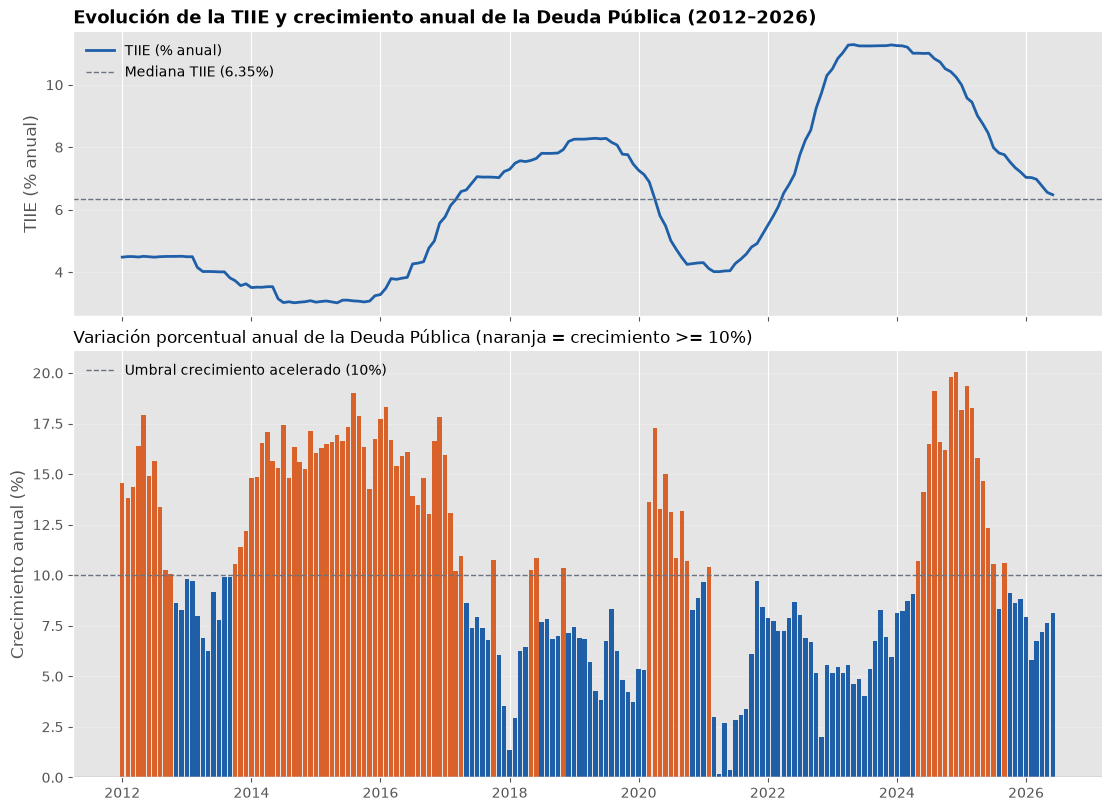

In [18]:
#Gráfica 1
import os
os.makedirs("../docs/pregunta1", exist_ok=True)

AZUL, NARANJA, GRIS = "#1F5FA8", "#D9622B", "#6B7280"

pdf_deuda["FECHA"] = pd.to_datetime(pdf_deuda["CICLO"] + "-01")

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True, constrained_layout=True,
    gridspec_kw={"height_ratios": (2, 3)}
)

# Panel 1: TIIE
ax1.plot(pdf_deuda["FECHA"], pdf_deuda["TIIE"], color=AZUL, lw=2, label="TIIE (% anual)")
ax1.axhline(pdf_deuda["TIIE_MEDIANA"].iloc[0], color=GRIS, lw=1, ls="--",
            label=f"Mediana TIIE ({pdf_deuda['TIIE_MEDIANA'].iloc[0]:.2f}%)")
ax1.set_title("Evolución de la TIIE y crecimiento anual de la Deuda Pública (2012–2026)", loc="left", fontsize=13, fontweight="bold")
ax1.set_ylabel("TIIE (% anual)")
ax1.legend(frameon=False, loc="upper left")
ax1.grid(axis="y", alpha=0.25)

# Panel 2: Crecimiento anual de la Deuda Pública
colores_deuda = [NARANJA if v >= 10.0 else AZUL for v in pdf_deuda["CREC_DEUDA_ANUAL"]]
ax2.bar(pdf_deuda["FECHA"], pdf_deuda["CREC_DEUDA_ANUAL"], width=25, color=colores_deuda)
ax2.axhline(10.0, color=GRIS, lw=1, ls="--", label="Umbral crecimiento acelerado (10%)")
ax2.axhline(0, color=GRIS, lw=1)
ax2.set_title("Variación porcentual anual de la Deuda Pública (naranja = crecimiento >= 10%)", loc="left", fontsize=12)
ax2.set_ylabel("Crecimiento anual (%)")
ax2.legend(frameon=False, loc="upper left")
ax2.grid(axis="y", alpha=0.25)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig("../docs/pregunta1/tiie_deuda_crecimiento.png", dpi=150)
plt.show()

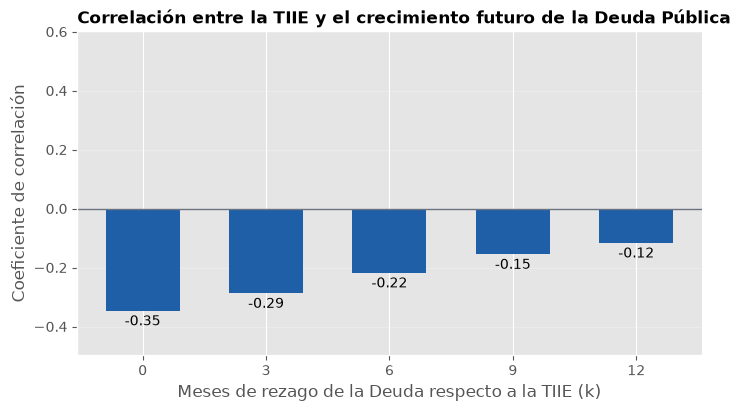

In [19]:
#Gráfica 2
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
colores_corr_d = [NARANJA if v >= 0 else AZUL for v in corr_deuda["CORRELACION"]]
barras = ax.bar(corr_deuda["REZAGO_MESES"].astype(str), corr_deuda["CORRELACION"], color=colores_corr_d, width=0.6)
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.axhline(0, color=GRIS, lw=1)
ax.set_ylim(min(-0.4, corr_deuda["CORRELACION"].min() - 0.15), max(0.6, corr_deuda["CORRELACION"].max() + 0.15))
ax.set_title("Correlación entre la TIIE y el crecimiento futuro de la Deuda Pública", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Meses de rezago de la Deuda respecto a la TIIE (k)")
ax.set_ylabel("Coeficiente de correlación")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

fig.savefig("../docs/pregunta1/tiie_deuda_rezagos.png", dpi=150)
plt.show()

### 3.5 Limitaciones e interpretación

- **Composición y vencimientos de la deuda:** La columna `DEUDA` representa el saldo agregado de la deuda pública sin desagregar entre tasa fija y tasa variable, ni entre deuda interna (en pesos) y externa (en moneda extranjera); una parte importante de la deuda a tasa fija no se encarece de inmediato ante alzas de la TIIE.
- **Efecto de valuación por tipo de cambio:** El componente externo de la deuda pública fluctúa mensualmente con el tipo de cambio peso-dólar, lo que puede provocar variaciones interanuales en el saldo reportado en pesos independientes de la TIIE.
- **Déficit fiscal y necesidades de financiamiento:** el crecimiento del saldo de la deuda obedece principalmente al déficit primario y a decisiones presupuestarias del Gobierno Federal (como el paquete contracíclico o de inversión pública), por lo que la correlación bivariada con la TIIE no implica causalidad única.
- **Cobertura y pérdida inicial de 12 meses:** Aunque el Parquet inicia en `2011-01`, el cálculo de variación anual (`LAG(..., 12)`) reduce la muestra efectiva a 174 meses (`2012-01` a `2026-06`).
- **Alcance:** Este análisis evalúa el eslabón *TIIE → Deuda Pública*; su interacción con la inflación (INPC) y la actividad económica (IGAE) se complementa en las Preguntas Analíticas 2 y 3.

### 3.6 Arquitectura aplicada

Recorrido completo de los datos desde las fuentes hasta el consumo analítico de las 3 preguntas de investigación:

```text
 Fuentes (data/raw)     Procesamiento       Almacenamiento          Consulta (Spark SQL)      Resultado Analítico
┌──────────────────┐   ┌───────────────┐   ┌───────────────────┐   ┌─────────────────────┐   ┌────────────────────┐
│ Banxico (TIIE)   │──▶│ Pipeline      │──▶│ macro_finanzas_   │──▶│ Vistas temporales:  │──▶│ Indicadores y      │
│ INEGI (IGAE/INPC)│   │ PySpark       │   │ consolidado.      │   │ - macro_deuda (P1)  │   │ correlaciones      │
│ SHCP (Deuda y    │   │ (ETL/Clean/   │   │ parquet           │   │ - macro / tasa_real │   │ + gráficas PNG en  │
│  Finanzas Púb.)  │   │  Validate)    │   │ (data/processed/) │   │ - macro_igae (P3)   │   │   docs/pregunta1..3│
└──────────────────┘   └───────────────┘   └───────────────────┘   └─────────────────────┘   └────────────────────┘
```

- **Almacenamiento y reutilización:** El dataset consolidado persiste en disco en formato columnar **Parquet** (`data/processed/macro_finanzas_consolidado.parquet`), lo que permite proyectar únicamente las columnas requeridas en cada pregunta (`CICLO`, `TIIE`, `DEUDA`, `VALOR_INPC`, `MONTO_IGAE_TOTAL`) mediante *column pruning*. Las vistas Spark SQL viven en memoria durante la sesión del notebook sin duplicar archivos procesados.
- **Implementado vs. evolución futura:** Actualmente se utiliza almacenamiento local en Parquet + consultas Spark SQL sobre vistas temporales + exportación estática de figuras PNG. Como evolución futura hacia un entorno tipo **Lakehouse (Delta Lake)**, se podrían versionar las tablas consolidadas y materializar las variaciones porcentuales anuales (`CREC_DEUDA_ANUAL`, `INFLACION_ANUAL`, `CREC_IGAE_ANUAL`) dentro de la capa `processed` del pipeline (`enrich.py`) para que múltiples consumidores las reutilicen sin recalcular funciones de ventana.
- **Incorporación de nuevos datos o correcciones:** Al publicarse nuevos cortes mensuales de Banxico, INEGI o SHCP (o revisiones de cifras preliminares), basta con actualizar los archivos fuente en `data/raw/`, reejecutar `pipeline.py` para regenerar el Parquet consolidado y correr nuevamente el notebook; las aserciones de integridad (`assert`) validan automáticamente que no existan nulos, duplicados ni meses faltantes antes de generar los reportes.

### Reproducibilidad del análisis
1. Ejecutar el pipeline principal para generar `data/processed/macro_finanzas_consolidado.parquet`.
2. Abrir `notebooks/reporte_de_proyecto.ipynb` desde `notebooks/` (o desde la raíz del repositorio) en un entorno con `pyspark`, `pandas` y `matplotlib`.
3. Ejecutar todas las celdas en orden: las evidencias gráficas se guardarán automáticamente en `docs/pregunta1/`, `docs/pregunta2/` y `docs/pregunta3/`.

### 4. Pregunta Analítica 2
> **¿Ha sido la tasa de interés real positiva en México entre 2012 y 2026, y reacciona la TIIE a la inflación medida con el INPC?**

Se divide en dos partes que responden las consultas de la sección siguiente:

1. **Nivel:** comparando la TIIE con la inflación anual, ¿qué tan seguido y por cuánto la tasa real (TIIE menos inflación) fue negativa?
2. **Reacción:** ¿se mueve la TIIE junto con la inflación o después de ella? ¿con cuántos meses de rezago?

**Por qué importa:** una tasa real negativa significa que el dinero prestado se abarata en términos de poder adquisitivo, lo que afecta ahorradores, deudores y el costo real del financiamiento público.

In [5]:
spark = (
    SparkSession.builder
    .appName("Actividad12_TIIE_INPC")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

# Rutas candidatas, de la más a la menos preferida. Ajusta la primera si el
# Parquet integrado del pipeline tiene otro nombre en tu repositorio.
CANDIDATAS = [
    "data/processed/macro_finanzas_consolidado.parquet",
    "data/raw/macro_finanzas_consolidado.csv",
    "macro_finanzas_consolidado.csv",
]
CANDIDATAS = CANDIDATAS + ["../" + c for c in CANDIDATAS]  # por si el notebook está en notebooks/

ruta = next((c for c in CANDIDATAS if Path(c).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró el dataset en ninguna de estas rutas: {CANDIDATAS}")

if ruta.endswith(".parquet"):
    crudo = spark.read.parquet(ruta)
else:
    crudo = spark.read.csv(ruta, header=True, inferSchema=True)

# Sólo se necesitan tres columnas para esta pregunta.
macro = crudo.select(
    F.col("CICLO").cast("string").alias("CICLO"),
    F.col("TIIE").cast("double").alias("TIIE"),
    F.col("VALOR_INPC").cast("double").alias("VALOR_INPC"),
)
macro.createOrReplaceTempView("macro")

print(f"[FUENTE] {ruta}")
macro.printSchema()
macro.show(5)

[FUENTE] ../data/processed/macro_finanzas_consolidado.parquet
root
 |-- CICLO: string (nullable = true)
 |-- TIIE: double (nullable = true)
 |-- VALOR_INPC: double (nullable = true)

+-------+------------------+---------------+
|  CICLO|              TIIE|     VALOR_INPC|
+-------+------------------+---------------+
|2011-01|4.5495238095238095|75.295991345634|
|2011-02| 4.518421052631578|75.578460244005|
|2011-03| 4.488636363636363|75.723450928541|
|2011-04| 4.504736842105263| 75.71744095198|
|2011-05| 4.466363636363637|75.159264378869|
+-------+------------------+---------------+
only showing top 5 rows



## 4.1. Descripción del dataset final

| Elemento | Descripción |
|---|---|
| **Origen** | `macro_finanzas_consolidado`: dataset integrado por el pipeline PySpark a partir de las fuentes del proyecto (deuda, finanzas públicas, IGAE, TIIE e INPC). |
| **Columnas usadas** | `CICLO` (mes, texto `AAAA-MM`), `TIIE` (tasa de interés interbancaria de equilibrio, en % anual) y `VALOR_INPC` (nivel del índice nacional de precios al consumidor). |
| **Periodo cubierto** | Se calcula en la celda siguiente (de enero de 2011 a junio de 2026 en la versión actual). |
| **Granularidad** | Una fila por mes, sin cortes por actividad ni por región. |

Antes de consultar se comprueban las condiciones que la pregunta necesita: sin nulos en las dos columnas, sin meses repetidos y sin huecos en la serie. Esto último importa porque el cálculo de inflación anual compara cada mes con el de 12 filas atrás.

In [6]:
resumen = spark.sql("""
    SELECT COUNT(*)                AS FILAS,
           COUNT(DISTINCT CICLO)   AS MESES_DISTINTOS,
           MIN(CICLO)              AS PRIMER_MES,
           MAX(CICLO)              AS ULTIMO_MES,
           SUM(CASE WHEN TIIE IS NULL THEN 1 ELSE 0 END)       AS NULOS_TIIE,
           SUM(CASE WHEN VALOR_INPC IS NULL THEN 1 ELSE 0 END) AS NULOS_INPC
    FROM macro
""").first()

meses_esperados = (
    (int(resumen.ULTIMO_MES[:4]) - int(resumen.PRIMER_MES[:4])) * 12
    + int(resumen.ULTIMO_MES[5:7]) - int(resumen.PRIMER_MES[5:7]) + 1
)

assert resumen.NULOS_TIIE == 0 and resumen.NULOS_INPC == 0, "Hay nulos en TIIE o VALOR_INPC"
assert resumen.FILAS == resumen.MESES_DISTINTOS, "Hay meses duplicados"
assert resumen.FILAS == meses_esperados, f"Hay huecos: {resumen.FILAS} filas vs {meses_esperados} meses esperados"

print(f"Periodo: {resumen.PRIMER_MES} a {resumen.ULTIMO_MES} | {resumen.FILAS} meses | validaciones OK")

Periodo: 2011-01 a 2026-06 | 186 meses | validaciones OK


## 4.2. Consultas de consumo (Spark SQL)

### Qué se calcula una vez en el pipeline y qué se calcula al consultar

| Resultado | Dónde se obtiene | Comentario |
|---|---|---|
| Unión de fuentes, limpieza, `CICLO` mensual, `TIIE`, `VALOR_INPC` | **Pipeline (ya preparado)** | Se consume tal cual; no se reprocesa. |
| Inflación anual a partir del INPC | **Consulta 1 (al consultar)** | Depende de la definición elegida para esta pregunta (variación contra el mismo mes del año anterior). |
| Tasa real y marca de tasa real negativa | **Consulta 1 (al consultar)** | Derivada de la inflación anual. |
| Resumen anual | **Consulta 2 (al consultar)** | Agregación ligera sobre la vista de la consulta 1. |
| Correlaciones con rezago | **Consulta 3 (al consultar)** | Se recalcula con cada rezago que se pruebe. |

Si el equipo decide que la inflación anual se usará en otras preguntas, puede moverse al ETL (`enrich.py`) en una iteración posterior; por ahora se mantiene en la capa de consumo para no tocar el pipeline.

### Consulta 1 — Inflación anual y tasa real

In [7]:
tasa_real = spark.sql("""
    WITH base AS (
        SELECT CICLO,
               TIIE,
               VALOR_INPC,
               ROUND((VALOR_INPC / LAG(VALOR_INPC, 12) OVER (ORDER BY CICLO) - 1) * 100, 4) AS INFLACION_ANUAL
        FROM macro
    )
    SELECT CICLO,
           TIIE,
           VALOR_INPC,
           INFLACION_ANUAL,
           ROUND(TIIE - INFLACION_ANUAL, 4)                         AS TASA_REAL,
           CASE WHEN TIIE - INFLACION_ANUAL < 0 THEN 1 ELSE 0 END   AS TASA_REAL_NEGATIVA
    FROM base
    WHERE INFLACION_ANUAL IS NOT NULL      -- los primeros 12 meses no tienen mes comparable
    ORDER BY CICLO
""")
tasa_real.createOrReplaceTempView("tasa_real")
tasa_real.cache()

print(f"Filas con inflación anual calculable: {tasa_real.count()}")
tasa_real.show(5)
tasa_real.orderBy(F.col("CICLO").desc()).show(3)

Filas con inflación anual calculable: 174
+-------+------------------+---------------+---------------+---------+------------------+
|  CICLO|              TIIE|     VALOR_INPC|INFLACION_ANUAL|TASA_REAL|TASA_REAL_NEGATIVA|
+-------+------------------+---------------+---------------+---------+------------------+
|2012-01|4.4790909090909095|78.343049462107|         4.0468|   0.4323|                 0|
|2012-02|             4.497|78.502313840976|         3.8686|   0.6284|                 0|
|2012-03| 4.497619047619048|78.547388665184|         3.7293|   0.7683|                 0|
|2012-04| 4.483157894736842|78.300979626179|         3.4121|   1.0711|                 0|
|2012-05| 4.505454545454546|78.053819340105|         3.8512|   0.6543|                 0|
+-------+------------------+---------------+---------------+---------+------------------+
only showing top 5 rows

+-------+-----------------+----------+---------------+---------+------------------+
|  CICLO|             TIIE|VALOR_INPC|I

### Consulta 2 — Resumen por año

In [8]:
por_anio = spark.sql("""
    SELECT SUBSTR(CICLO, 1, 4)              AS ANIO,
           COUNT(*)                         AS MESES,
           ROUND(AVG(TIIE), 2)              AS TIIE_PROM,
           ROUND(AVG(INFLACION_ANUAL), 2)   AS INFLACION_PROM,
           ROUND(AVG(TASA_REAL), 2)         AS TASA_REAL_PROM,
           SUM(TASA_REAL_NEGATIVA)          AS MESES_TASA_REAL_NEG
    FROM tasa_real
    GROUP BY SUBSTR(CICLO, 1, 4)
    ORDER BY ANIO
""")
por_anio.show(20)

+----+-----+---------+--------------+--------------+-------------------+
|ANIO|MESES|TIIE_PROM|INFLACION_PROM|TASA_REAL_PROM|MESES_TASA_REAL_NEG|
+----+-----+---------+--------------+--------------+-------------------+
|2012|   12|      4.5|          4.11|          0.38|                  3|
|2013|   12|     3.99|          3.81|          0.19|                  6|
|2014|   12|     3.25|          4.02|         -0.77|                 10|
|2015|   12|     3.08|          2.72|          0.35|                  3|
|2016|   12|     4.18|          2.82|          1.36|                  0|
|2017|   12|     6.73|          6.04|          0.69|                  0|
|2018|   12|      7.7|           4.9|           2.8|                  0|
|2019|   12|     8.09|          3.64|          4.45|                  0|
|2020|   12|     5.49|           3.4|           2.1|                  0|
|2021|   12|     4.39|          5.68|         -1.29|                 10|
|2022|   12|     7.64|          7.89|         -0.25

### Consulta 3 — ¿La TIIE sigue a la inflación? Correlación con rezagos

Se correlaciona la inflación anual de un mes con la TIIE de `k` meses después. Si la TIIE reaccionara de inmediato, la correlación más alta estaría en `k = 0`; si reacciona con retraso, crecerá al aumentar `k`.

In [9]:
REZAGOS = [0, 3, 6, 9, 12]
partes = []
for k in REZAGOS:
    tiie_futura = "TIIE" if k == 0 else f"LEAD(TIIE, {k}) OVER (ORDER BY CICLO)"
    partes.append(f"""
        SELECT {k} AS REZAGO_MESES,
               COUNT(*) AS N_MESES,
               ROUND(CORR(INFLACION_ANUAL, TIIE_FUTURA), 4) AS CORRELACION
        FROM (SELECT INFLACION_ANUAL, {tiie_futura} AS TIIE_FUTURA FROM tasa_real)
        WHERE TIIE_FUTURA IS NOT NULL
    """)

rezagos_df = spark.sql(" UNION ALL ".join(partes)).orderBy("REZAGO_MESES")
rezagos_df.show()

+------------+-------+-----------+
|REZAGO_MESES|N_MESES|CORRELACION|
+------------+-------+-----------+
|           0|    174|     0.3844|
|           3|    171|     0.5122|
|           6|    168|     0.6096|
|           9|    165|     0.6806|
|          12|    162|     0.7216|
+------------+-------+-----------+



## 4.3. Indicadores y hallazgos

La celda siguiente recoge los resultados de Spark en pandas (son pocas filas) y calcula los indicadores directamente desde ellos, de modo que los números del texto siempre se pueden verificar.

In [10]:
pdf = tasa_real.toPandas()
anual = por_anio.toPandas()
corr = rezagos_df.toPandas()

n = len(pdf)
neg = int(pdf["TASA_REAL_NEGATIVA"].sum())
fila_min = pdf.loc[pdf["TASA_REAL"].idxmin()]
fila_max = pdf.loc[pdf["TASA_REAL"].idxmax()]
mejor = corr.loc[corr["CORRELACION"].idxmax()]
corr0 = float(corr.loc[corr["REZAGO_MESES"] == 0, "CORRELACION"].iloc[0])

print("INDICADOR 1 · Nivel de la tasa real")
print(f"  Tasa real promedio: {pdf['TASA_REAL'].mean():.2f} pp ({pdf['CICLO'].iloc[0]} a {pdf['CICLO'].iloc[-1]})")
print(f"  Meses con tasa real negativa: {neg} de {n} ({neg / n:.1%})")
print(f"  Mínimo: {fila_min['TASA_REAL']:.2f} pp en {fila_min['CICLO']} (TIIE {fila_min['TIIE']:.2f}%, inflación {fila_min['INFLACION_ANUAL']:.2f}%)")
print(f"  Máximo: {fila_max['TASA_REAL']:.2f} pp en {fila_max['CICLO']} (TIIE {fila_max['TIIE']:.2f}%, inflación {fila_max['INFLACION_ANUAL']:.2f}%)")
print()
print("INDICADOR 2 · Reacción de la TIIE a la inflación")
print(f"  Correlación sin rezago: {corr0:.2f}")
print(f"  Correlación más alta: {mejor['CORRELACION']:.2f} con TIIE {int(mejor['REZAGO_MESES'])} meses después")

INDICADOR 1 · Nivel de la tasa real
  Tasa real promedio: 1.91 pp (2012-01 a 2026-06)
  Meses con tasa real negativa: 41 de 174 (23.6%)
  Mínimo: -2.46 pp en 2021-11 (TIIE 4.91%, inflación 7.37%)
  Máximo: 7.00 pp en 2023-10 (TIIE 11.25%, inflación 4.26%)

INDICADOR 2 · Reacción de la TIIE a la inflación
  Correlación sin rezago: 0.38
  Correlación más alta: 0.72 con TIIE 12 meses después


### Hallazgos (con la corrida de referencia, datos de 2011-01 a 2026-06)

**Hallazgo 1 — La tasa real fue positiva la mayor parte del tiempo, pero con episodios claros de tasa negativa.**
De los 174 meses con inflación anual calculable (2012-01 a 2026-06), 41 (23.6%) tuvieron tasa real negativa y el promedio fue de 1.91 puntos porcentuales. Los meses negativos se concentran en 2013–2014 y en 2021–2022; el mínimo fue de −2.46 pp en noviembre de 2021 (TIIE 4.91% frente a inflación de 7.37%). En el extremo opuesto, la tasa real llegó a 7.00 pp en octubre de 2023, con una TIIE cercana a 11.25% y una inflación de 4.26%.

**Hallazgo 2 — La TIIE reacciona a la inflación con retraso, no de inmediato.**
La correlación entre la inflación de un mes y la TIIE del mismo mes es de 0.38, pero sube de forma sostenida con el rezago: 0.51 a 3 meses, 0.61 a 6, 0.68 a 9 y 0.72 a 12 meses. Esto es coherente con una política monetaria que responde a la inflación ya observada. El ciclo 2021–2023 lo ilustra: la inflación se aceleró desde 2021, la tasa real fue negativa mientras la TIIE seguía baja, y la TIIE alcanzó su máximo de 11.29% hasta mayo de 2023.

**Lectura reciente.** Con la información disponible hasta junio de 2026, la TIIE (6.48%) se encuentra por encima de la inflación anual (3.37%), con una tasa real de alrededor de 3.1 pp.

> Los valores se recalculan en la celda anterior; si el dataset cambia, estos párrafos deben actualizarse.

## 4.4. Visualización

El primer panel muestra la TIIE frente a la inflación anual; el área roja marca los meses en que la inflación estuvo por encima de la TIIE (tasa real negativa). El segundo muestra la tasa real mes a mes.

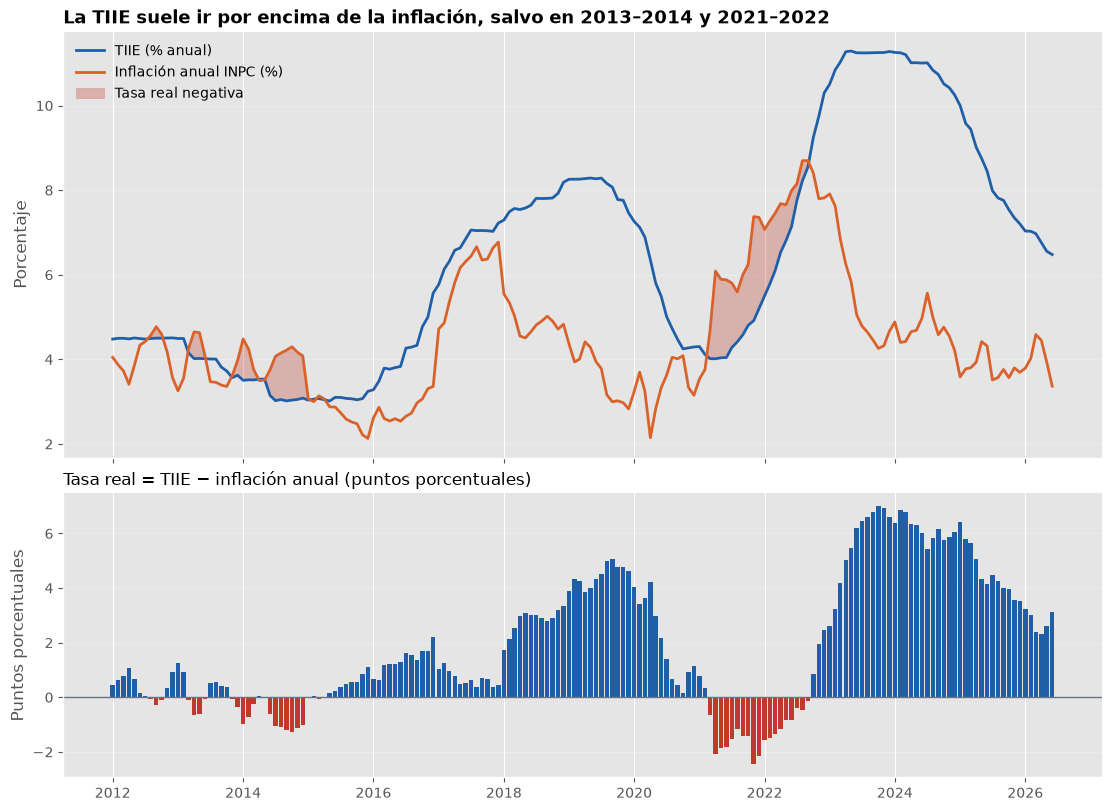

In [11]:
import os
os.makedirs("../docs/pregunta2", exist_ok=True)

AZUL, NARANJA, ROJO, GRIS = "#1F5FA8", "#D9622B", "#C0392B", "#6B7280"

pdf["FECHA"] = pd.to_datetime(pdf["CICLO"] + "-01")
neg_mask = (pdf["TASA_REAL"] < 0).to_numpy()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True,
                               gridspec_kw={"height_ratios": [3, 2]})

# Panel 1: TIIE vs inflación anual
ax1.plot(pdf["FECHA"], pdf["TIIE"], color=AZUL, lw=2, label="TIIE (% anual)")
ax1.plot(pdf["FECHA"], pdf["INFLACION_ANUAL"], color=NARANJA, lw=2, label="Inflación anual INPC (%)")
ax1.fill_between(pdf["FECHA"], pdf["TIIE"], pdf["INFLACION_ANUAL"], where=neg_mask,
                 interpolate=True, color=ROJO, alpha=0.30, label="Tasa real negativa")
ax1.set_title("La TIIE suele ir por encima de la inflación, salvo en 2013–2014 y 2021–2022", loc="left", fontsize=13, fontweight="bold")
ax1.set_ylabel("Porcentaje")
ax1.legend(frameon=False, loc="upper left")
ax1.grid(axis="y", alpha=0.25)

# Panel 2: tasa real
colores = [ROJO if v < 0 else AZUL for v in pdf["TASA_REAL"]]
ax2.bar(pdf["FECHA"], pdf["TASA_REAL"], width=25, color=colores)
ax2.axhline(0, color=GRIS, lw=1)
ax2.set_title("Tasa real = TIIE − inflación anual (puntos porcentuales)", loc="left", fontsize=12)
ax2.set_ylabel("Puntos porcentuales")
ax2.grid(axis="y", alpha=0.25)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig("../docs/pregunta2/tiie_inpc_tasa_real.png", dpi=150)
plt.show()

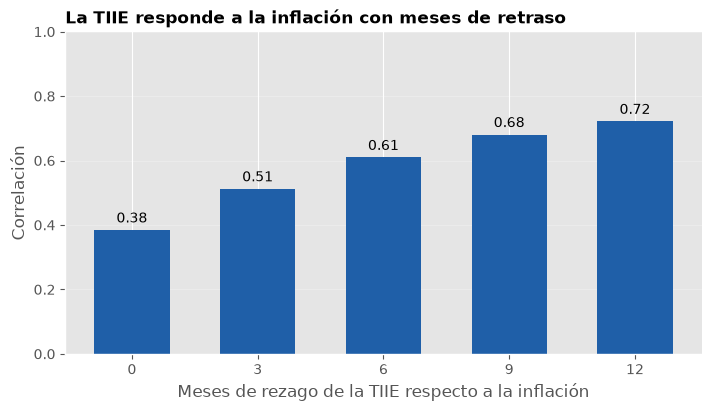

In [12]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
barras = ax.bar(corr["REZAGO_MESES"].astype(str), corr["CORRELACION"], color=AZUL, width=0.6)
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.set_ylim(0, 1)
ax.set_title("La TIIE responde a la inflación con meses de retraso", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Meses de rezago de la TIIE respecto a la inflación")
ax.set_ylabel("Correlación")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

fig.savefig("../docs/pregunta2/tiie_inflacion_rezagos.png", dpi=150)
plt.show()

## 4.5 Limitaciones e interpretación prudente

- **Tasa real ex post.** Se compara la TIIE con la inflación que efectivamente ocurrió, no con la inflación que los agentes esperaban al fijar la tasa. Una tasa real "negativa" en el cálculo no implica que fuera negativa ex ante.
- **Correlación no es causalidad.** Que la TIIE siga a la inflación con rezago es consistente con una política monetaria reactiva, pero con una sola serie mensual no se puede aislar el efecto de la tasa sobre la inflación ni de otros factores (tipo de cambio, choques externos, expectativas).
- **Series con tendencia.** Las correlaciones entre series persistentes pueden inflarse por comovimientos largos; deben leerse como indicio descriptivo, no como estimación de un efecto.
- **Cobertura temporal.** Los datos van de 2011-01 a 2026-06. La inflación anual necesita 12 meses previos, por lo que el análisis de tasa real comienza en 2012-01 y los resultados dependen de los ciclos que caen en esa ventana.
- **Definición de las variables.** `TIIE` se toma como viene en el dataset (promedio mensual, según los decimales que presenta) y `VALOR_INPC` como nivel del índice; conviene confirmar con la documentación de la fuente el plazo de la TIIE y la base del INPC antes de publicar conclusiones.
- **Alcance.** Este bloque no incorpora deuda, ingresos ni gasto públicos; cualquier afirmación sobre su relación con la tasa real corresponde a otras preguntas del equipo.

### 4.6 Arquitectura aplicada

Recorrido de los datos en el proyecto y lugar de este notebook:

```text
 Fuentes (CSV en data/raw)        Procesamiento             Almacenamiento            Consulta               Resultado
┌─────────────────────────┐     ┌────────────────┐        ┌──────────────────┐     ┌────────────────┐     ┌───────────────────────┐
│ deuda, finanzas, IGAE,  │ ──▶ │ PySpark (src/) │  ───▶  │ Parquet integrado│ ──▶ │ Spark SQL en   │ ──▶ │ Tablas e indicadores  │
│ TIIE, INPC              │     │ extract, clean,│        │ (data/processed) │     │ este notebook  │     │ + gráficas en         │
│                         │     │ validate, load │        │ mensual (CICLO)  │     │ (vistas tasa_  │     │ ..docs/pregunta2/     │
└─────────────────────────┘     └────────────────┘        └──────────────────┘     │ real, macro)   │     └───────────────────────┘
                                                                                    └────────────────┘
```

**Dónde se almacenan y cómo se reutilizan.** El pipeline deja el dataset integrado en formato Parquet, en disco local. El notebook lo lee con Spark, registra vistas temporales (`macro`, `tasa_real`) y ejecuta las consultas sin reescribir el dato base. Las vistas viven sólo mientras dura la sesión de Spark; lo que se conserva es el Parquet y las figuras guardadas en `..docs/pregunta2/`.

**Implementado hoy:** lectura de Parquet/CSV, consultas Spark SQL sobre vistas temporales y gráficas con matplotlib.
**Posible evolución (no implementada):** publicar la tabla de resultados en un Data Lake o Lakehouse con tablas versionadas, o mover la inflación anual y la tasa real al ETL si más preguntas las necesitan.

**Cómo se incorporarían nuevos datos o correcciones.** Se agregarían los meses nuevos a las fuentes de `data/raw` (o se corregiría el valor erróneo), se volvería a ejecutar el pipeline para regenerar el Parquet y se reejecutaría este notebook de arriba abajo. Las validaciones de la sección 2 detectan meses repetidos, huecos o nulos antes de calcular. No se implementa carga incremental porque el volumen (unos 186 registros) no la justifica.

### Cómo reproducir
1. Ejecutar el pipeline para generar el Parquet integrado (o dejar `macro_finanzas_consolidado.csv` en `data/raw/`).
2. Abrir este notebook desde la raíz del repositorio (o desde `notebooks/`) con PySpark, pandas y matplotlib instalados.
3. Ejecutar todas las celdas en orden. Las figuras se guardan en `..docs/pregunta2/`.

## 5. Pregunta Analítica 3  
**¿En qué medida los incrementos en la Tasa de Interés Interbancaria de Equilibrio (TIIE) frenan el dinamismo de la actividad económica medida por el Indicador Global de la Actividad Económica (IGAE) entre 2012 y 2026, y con cuántos meses de rezago se manifiesta este enfriamiento?**

Se divide en dos partes que responden las consultas de la sección siguiente:

1. **Comportamiento por régimen monetario:** Comparando el crecimiento anual del IGAE en periodos de política restrictiva (TIIE por encima de su mediana histórica) frente a periodos acomodaticios, ¿se desacelera efectivamente la actividad económica cuando sube el costo del dinero?
2. **Rezago de transmisión:** ¿El impacto de un movimiento en la TIIE sobre el crecimiento del IGAE ocurre de forma inmediata o con retraso? ¿en qué ventana de meses (`k = 0, 3, 6, 9, 12`) se observa la correlación negativa más marcada?

**Por qué importa:** El canal de tasas de interés sobre la actividad real (consumo e inversión) es el puente entre las decisiones de Banxico y las finanzas públicas, ya que una desaceleración del IGAE reduce la base gravable y la recaudación tributaria de la SHCP.

In [2]:
#Carga del archivo parquet y creación de vista en Spark
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

plt.style.use("ggplot")

spark = (
    SparkSession.builder
    .appName("Actividad12_TIIE_IGAE")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

CANDIDATAS = [
    "data/processed/macro_finanzas_consolidado.parquet",
    "data/raw/macro_finanzas_consolidado.csv",
    "macro_finanzas_consolidado.csv",
]
CANDIDATAS = CANDIDATAS + ["../" + c for c in CANDIDATAS]

ruta = next((c for c in CANDIDATAS if Path(c).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró el dataset en ninguna de estas rutas: {CANDIDATAS}")

if ruta.endswith(".parquet"):
    crudo = spark.read.parquet(ruta)
else:
    crudo = spark.read.csv(ruta, header=True, inferSchema=True)

# Selección de las tres columnas necesarias para esta pregunta
macro_igae = crudo.select(
    F.col("CICLO").cast("string").alias("CICLO"),
    F.col("TIIE").cast("double").alias("TIIE"),
    F.col("MONTO_IGAE_TOTAL").cast("double").alias("MONTO_IGAE_TOTAL"),
)
macro_igae.createOrReplaceTempView("macro_igae")

print(f"[FUENTE] {ruta}")
macro_igae.printSchema()
macro_igae.show(5)

[FUENTE] ../data/processed/macro_finanzas_consolidado.parquet
root
 |-- CICLO: string (nullable = true)
 |-- TIIE: double (nullable = true)
 |-- MONTO_IGAE_TOTAL: double (nullable = true)

+-------+------------------+----------------+
|  CICLO|              TIIE|MONTO_IGAE_TOTAL|
+-------+------------------+----------------+
|2011-01|4.5495238095238095|81.0595403368419|
|2011-02| 4.518421052631578|80.1156149128606|
|2011-03| 4.488636363636363|87.1736739506537|
|2011-04| 4.504736842105263| 82.957170328975|
|2011-05| 4.466363636363637|86.0386317656384|
+-------+------------------+----------------+
only showing top 5 rows



### 5.1 Descripción del dataset final

| Elemento | Descripción |
|---|---|
| **Origen** | `macro_finanzas_consolidado.parquet`: Dataset maestro integrado por el pipeline PySpark a partir de las fuentes oficiales de Banxico, INEGI y SHCP. |
| **Columnas usadas** | `CICLO` (mes en formato `AAAA-MM`), `TIIE` (tasa de interés interbancaria de equilibrio, en % anual) y `MONTO_IGAE_TOTAL` (nivel del Indicador Global de la Actividad Económica del INEGI). |
| **Periodo cubierto** | Enero de 2011 (`2011-01`) a junio de 2026 (`2026-06`), totalizando 186 observaciones mensuales (174 meses con variación anual calculable a partir de `2012-01`). |
| **Granularidad** | Mensual a nivel nacional (una fila única por ciclo `AAAA-MM`, sin desagregación sectorial ni estatal). |

Antes de ejecutar las consultas analíticas se valida que no existan valores nulos, meses duplicados ni saltos en la secuencia temporal, requisito indispensable para calcular correctamente los rezagos de 12 meses (`LAG(MONTO_IGAE_TOTAL, 12)`).

In [3]:
#Validación de calidad antes del consumo
resumen_igae = spark.sql("""
    SELECT COUNT(*)                                            AS FILAS,
           COUNT(DISTINCT CICLO)                               AS MESES_DISTINTOS,
           MIN(CICLO)                                          AS PRIMER_MES,
           MAX(CICLO)                                          AS ULTIMO_MES,
           SUM(CASE WHEN TIIE IS NULL THEN 1 ELSE 0 END)       AS NULOS_TIIE,
           SUM(CASE WHEN MONTO_IGAE_TOTAL IS NULL THEN 1 ELSE 0 END) AS NULOS_IGAE
    FROM macro_igae
""").first()

meses_esperados = (
    (int(resumen_igae.ULTIMO_MES[:4]) - int(resumen_igae.PRIMER_MES[:4])) * 12
    + int(resumen_igae.ULTIMO_MES[5:7]) - int(resumen_igae.PRIMER_MES[5:7]) + 1
)

assert resumen_igae.NULOS_TIIE == 0 and resumen_igae.NULOS_IGAE == 0, "Hay nulos en TIIE o MONTO_IGAE_TOTAL"
assert resumen_igae.FILAS == resumen_igae.MESES_DISTINTOS, "Hay meses duplicados"
assert resumen_igae.FILAS == meses_esperados, f"Hay huecos: {resumen_igae.FILAS} filas vs {meses_esperados} meses esperados"

print(f"Periodo: {resumen_igae.PRIMER_MES} a {resumen_igae.ULTIMO_MES} | {resumen_igae.FILAS} meses | validaciones OK")


Periodo: 2011-01 a 2026-06 | 186 meses | validaciones OK


### 5.2 Consultas de consumo (Spark SQL)

### Lo que se calcula una vez en el pipeline y lo que se calcula al consultar

| Resultado | Dónde se obtiene | Comentario |
|---|---|---|
| Limpieza, homologación de `CICLO` mensual y cruce de `TIIE` con `MONTO_IGAE_TOTAL` | **Pipeline (`data/processed/`)** | Se lee directamente del Parquet consolidado sin reprocesar fuentes crudas. |
| Crecimiento anual del IGAE (`CREC_IGAE_ANUAL`) | **Consulta 1 (al consultar)** | Variación porcentual contra el mismo mes del año previo (`LAG(..., 12)`) para evitar distorsiones por estacionalidad mensual. |
| Clasificación de régimen monetario y contracción económica | **Consulta 1 (al consultar)** | Indicador derivado que compara la TIIE contra su mediana histórica del periodo analizado. |
| Desempeño anual promedio (`TIIE` vs. `IGAE`) | **Consulta 2 (al consultar)** | Agregación ligera sobre la vista `actividad_monetaria`. |
| Correlaciones cruzadas con rezagos (`k = 0, 3, 6, 9, 12`) | **Consulta 3 (al consultar)** | Evalúa el retraso temporal entre el movimiento de la TIIE y la respuesta del IGAE. |

### Consulta 1 — Crecimiento anual del IGAE y postura de política monetaria

In [4]:
actividad_monetaria = spark.sql("""
    WITH base AS (
        SELECT CICLO,
               TIIE,
               MONTO_IGAE_TOTAL,
               ROUND((MONTO_IGAE_TOTAL / LAG(MONTO_IGAE_TOTAL, 12) OVER (ORDER BY CICLO) - 1) * 100, 4) AS CREC_IGAE_ANUAL
        FROM macro_igae
    ),
    mediana AS (
        SELECT PERCENTILE_APPROX(TIIE, 0.5) AS TIIE_MEDIANA
        FROM base
        WHERE CREC_IGAE_ANUAL IS NOT NULL
    )
    SELECT b.CICLO,
           b.TIIE,
           b.MONTO_IGAE_TOTAL,
           b.CREC_IGAE_ANUAL,
           ROUND(m.TIIE_MEDIANA, 4)                                       AS TIIE_MEDIANA,
           CASE WHEN b.TIIE >= m.TIIE_MEDIANA THEN 'Restrictiva' ELSE 'Acomodaticia' END AS POSTURA_MONETARIA,
           CASE WHEN b.CREC_IGAE_ANUAL < 0 THEN 1 ELSE 0 END              AS CONTRACCION_IGAE
    FROM base b
    CROSS JOIN mediana m
    WHERE b.CREC_IGAE_ANUAL IS NOT NULL
    ORDER BY b.CICLO
""")
actividad_monetaria.createOrReplaceTempView("actividad_monetaria")
actividad_monetaria.cache()

print(f"Filas con crecimiento anual del IGAE calculable: {actividad_monetaria.count()}")
actividad_monetaria.show(5)
actividad_monetaria.orderBy(F.col("CICLO").desc()).show(3)

Filas con crecimiento anual del IGAE calculable: 174
+-------+------------------+----------------+---------------+------------+-----------------+----------------+
|  CICLO|              TIIE|MONTO_IGAE_TOTAL|CREC_IGAE_ANUAL|TIIE_MEDIANA|POSTURA_MONETARIA|CONTRACCION_IGAE|
+-------+------------------+----------------+---------------+------------+-----------------+----------------+
|2012-01|4.4790909090909095|  85.35761312417|         5.3024|      6.3535|     Acomodaticia|               0|
|2012-02|             4.497|85.2967647306931|         6.4671|      6.3535|     Acomodaticia|               0|
|2012-03| 4.497619047619048|90.1201109063992|           3.38|      6.3535|     Acomodaticia|               0|
|2012-04| 4.483157894736842|86.6708712535479|         4.4766|      6.3535|     Acomodaticia|               0|
|2012-05| 4.505454545454546|90.1259780424842|         4.7506|      6.3535|     Acomodaticia|               0|
+-------+------------------+----------------+---------------+------

### Consulta 2 — Resumen anual de TIIE y dinamismo del IGAE

In [5]:
#Consulta 2 en Spark
igae_por_anio = spark.sql("""
    SELECT SUBSTR(CICLO, 1, 4)              AS ANIO,
           COUNT(*)                         AS MESES,
           ROUND(AVG(TIIE), 2)              AS TIIE_PROM,
           ROUND(AVG(CREC_IGAE_ANUAL), 2)   AS CREC_IGAE_PROM,
           SUM(CONTRACCION_IGAE)            AS MESES_CONTRACCION
    FROM actividad_monetaria
    GROUP BY SUBSTR(CICLO, 1, 4)
    ORDER BY ANIO
""")
igae_por_anio.show(20)

+----+-----+---------+--------------+-----------------+
|ANIO|MESES|TIIE_PROM|CREC_IGAE_PROM|MESES_CONTRACCION|
+----+-----+---------+--------------+-----------------+
|2012|   12|      4.5|          3.66|                0|
|2013|   12|     3.99|          0.93|                4|
|2014|   12|     3.25|          2.49|                0|
|2015|   12|     3.08|          2.55|                0|
|2016|   12|     4.18|          1.79|                2|
|2017|   12|     6.73|          1.93|                1|
|2018|   12|      7.7|          2.05|                2|
|2019|   12|     8.09|         -0.42|                8|
|2020|   12|     5.49|         -8.01|               12|
|2021|   12|     4.39|          6.45|                3|
|2022|   12|     7.64|          3.48|                0|
|2023|   12|    11.14|          3.16|                0|
|2024|   12|    10.88|           1.4|                4|
|2025|   12|     8.41|          0.36|                7|
|2026|    6|      6.8|          1.14|           

### Consulta 3 — Rezago de transmisión: ¿Cuántos meses tarda la TIIE en impactar al IGAE?

Se correlaciona la `TIIE` de un mes `t` con el crecimiento anual del `IGAE` observado `k` meses después (`t + k`). De acuerdo con la teoría económica, una tasa más alta encarece el crédito y frena la inversión con retraso, por lo que se espera una **correlación negativa** que se intensifique conforme aumenta `k`.

In [6]:
#Consulta 3 en Spark
REZAGOS_IGAE = [0, 3, 6, 9, 12]
partes_igae = []
for k in REZAGOS_IGAE:
    igae_futuro = "CREC_IGAE_ANUAL" if k == 0 else f"LEAD(CREC_IGAE_ANUAL, {k}) OVER (ORDER BY CICLO)"
    partes_igae.append(f"""
        SELECT {k} AS REZAGO_MESES,
               COUNT(*) AS N_MESES,
               ROUND(CORR(TIIE, IGAE_FUTURO), 4) AS CORRELACION
        FROM (SELECT TIIE, {igae_futuro} AS IGAE_FUTURO FROM actividad_monetaria)
        WHERE IGAE_FUTURO IS NOT NULL
    """)

rezagos_igae_df = spark.sql(" UNION ALL ".join(partes_igae)).orderBy("REZAGO_MESES")
rezagos_igae_df.show()

+------------+-------+-----------+
|REZAGO_MESES|N_MESES|CORRELACION|
+------------+-------+-----------+
|           0|    174|    -0.0415|
|           3|    171|    -0.1164|
|           6|    168|    -0.1798|
|           9|    165|    -0.2247|
|          12|    162|    -0.2232|
+------------+-------+-----------+



## 5.3 Indicadores y hallazgos

La siguiente celda extrae las tablas resumidas a pandas para imprimir automáticamente los indicadores exactos del periodo y asegurar que la interpretación coincida al 100% con los datos del Parquet.

In [7]:
#Cálculo de indicadores
pdf_igae = actividad_monetaria.toPandas()
anual_igae = igae_por_anio.toPandas()
corr_igae = rezagos_igae_df.toPandas()

n_igae = len(pdf_igae)
contrac = int(pdf_igae["CONTRACCION_IGAE"].sum())
crec_restr = pdf_igae.loc[pdf_igae["POSTURA_MONETARIA"] == "Restrictiva", "CREC_IGAE_ANUAL"].mean()
crec_acom = pdf_igae.loc[pdf_igae["POSTURA_MONETARIA"] == "Acomodaticia", "CREC_IGAE_ANUAL"].mean()
min_igae = pdf_igae.loc[pdf_igae["CREC_IGAE_ANUAL"].idxmin()]
max_igae = pdf_igae.loc[pdf_igae["CREC_IGAE_ANUAL"].idxmax()]
corr_igae_0 = float(corr_igae.loc[corr_igae["REZAGO_MESES"] == 0, "CORRELACION"].iloc[0])
min_corr_row = corr_igae.loc[corr_igae["CORRELACION"].idxmin()]

print("INDICADOR 1 · Crecimiento del IGAE según postura monetaria")
print(f"  Crecimiento anual promedio del IGAE: {pdf_igae['CREC_IGAE_ANUAL'].mean():.2f}% ({pdf_igae['CICLO'].iloc[0]} a {pdf_igae['CICLO'].iloc[-1]})")
print(f"  Crecimiento promedio con TIIE Restrictiva (>= mediana {pdf_igae['TIIE_MEDIANA'].iloc[0]:.2f}%): {crec_restr:.2f}%")
print(f"  Crecimiento promedio con TIIE Acomodaticia (< mediana): {crec_acom:.2f}%")
print(f"  Meses con contracción anual del IGAE: {contrac} de {n_igae} ({contrac / n_igae:.1%})")
print(f"  Mínimo crecimiento: {min_igae['CREC_IGAE_ANUAL']:.2f}% en {min_igae['CICLO']} (TIIE {min_igae['TIIE']:.2f}%)")
print(f"  Máximo crecimiento: {max_igae['CREC_IGAE_ANUAL']:.2f}% en {max_igae['CICLO']} (TIIE {max_igae['TIIE']:.2f}%)")
print()
print("INDICADOR 2 · Rezago de transmisión TIIE -> IGAE")
print(f"  Correlación contemporánea (rezago 0): {corr_igae_0:.4f}")
print(f"  Correlación más negativa: {min_corr_row['CORRELACION']:.4f} con rezago de {int(min_corr_row['REZAGO_MESES'])} meses")

INDICADOR 1 · Crecimiento del IGAE según postura monetaria
  Crecimiento anual promedio del IGAE: 1.54% (2012-01 a 2026-06)
  Crecimiento promedio con TIIE Restrictiva (>= mediana 6.35%): 1.22%
  Crecimiento promedio con TIIE Acomodaticia (< mediana): 1.87%
  Meses con contracción anual del IGAE: 45 de 174 (25.9%)
  Mínimo crecimiento: -24.11% en 2020-05 (TIIE 5.80%)
  Máximo crecimiento: 27.71% en 2021-05 (TIIE 4.04%)

INDICADOR 2 · Rezago de transmisión TIIE -> IGAE
  Correlación contemporánea (rezago 0): -0.0415
  Correlación más negativa: -0.2247 con rezago de 9 meses


### Hallazgos

**Hallazgo 1 — El dinamismo del IGAE se modera bajo regímenes de TIIE restrictiva.**
En los 174 meses observables (`2012-01` a `2026-06`), el crecimiento anual promedio del IGAE es de **1.54%**, registrando contracciones anuales en **45 meses** (**25.9%** del periodo). Al dividir la muestra por la mediana histórica de la TIIE (**6.35%**), se observa que cuando la postura monetaria es **restrictiva** (`TIIE >= 6.35%`) la economía crece en promedio **1.22%** anual, frente a **1.87%** en periodos de tasa **acomodaticia** (`< 6.35%`) —una brecha de **0.65 puntos porcentuales**—. Los valores extremos corresponden al choque sanitario de `2020-05` (**-24.11%**, con TIIE de `5.80%`) y al rebote estadístico de `2021-05` (**+27.71%**, con TIIE de `4.04%`).

**Hallazgo 2 — La transmisión de la TIIE hacia la actividad real alcanza su mayor impacto a los 9 meses.**
La correlación contemporánea (`k = 0`) entre el nivel de la TIIE y el crecimiento anual del IGAE es prácticamente nula (**-0.0415**), lo que confirma que un movimiento en la tasa de referencia no frena la actividad productiva de manera inmediata. Sin embargo, la relación se vuelve progresivamente negativa hasta alcanzar su punto más bajo en **-0.2247 con un rezago de 9 meses**, consistente con la teoría monetaria: el encarecimiento del crédito tarda alrededor de tres trimestres en trasladarse plenamente hacia el consumo y la inversión real.

### 5.4 Visualización

El primer panel contrasta la trayectoria de la **TIIE** frente al **crecimiento anual del IGAE** (destacando en rojo los meses de contracción económica). El segundo panel muestra el **perfil de correlaciones con rezago** (`0` a `12` meses) para ilustrar el retraso del mecanismo de transmisión.

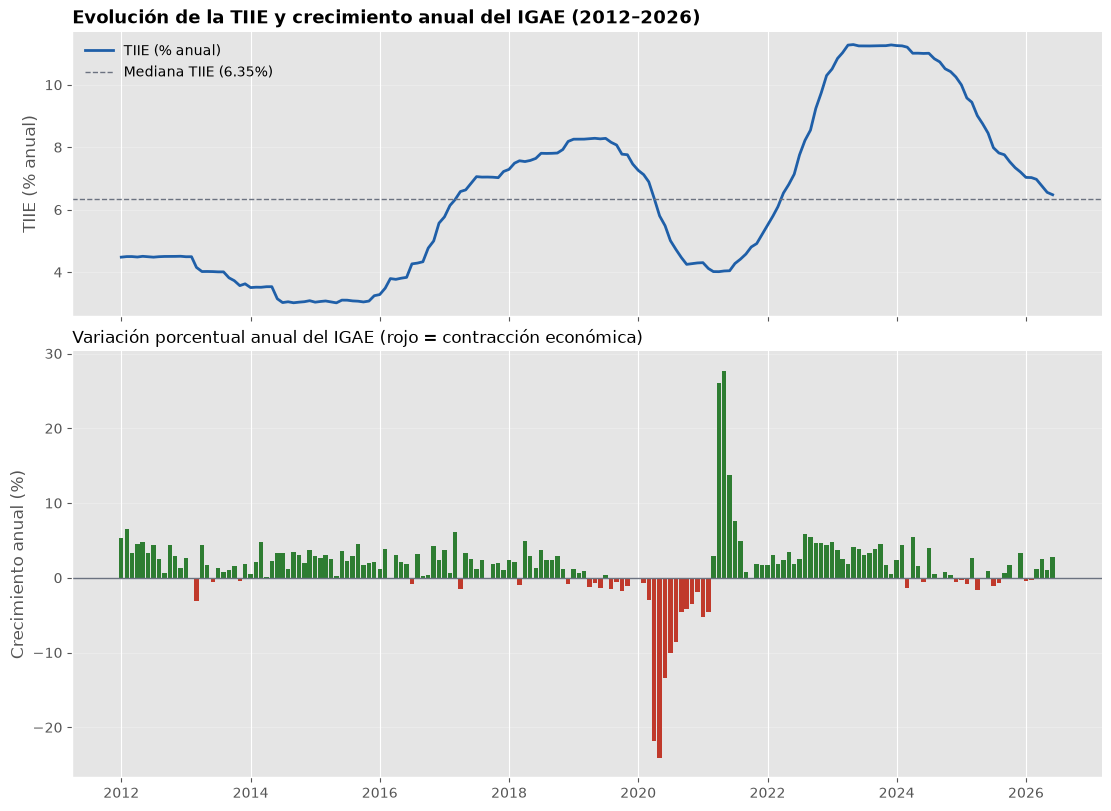

In [8]:
#Gráfica 1
import os
os.makedirs("../docs/pregunta3", exist_ok=True)

AZUL, VERDE, ROJO, GRIS = "#1F5FA8", "#2E7D32", "#C0392B", "#6B7280"

pdf_igae["FECHA"] = pd.to_datetime(pdf_igae["CICLO"] + "-01")
contrac_mask = (pdf_igae["CREC_IGAE_ANUAL"] < 0).to_numpy()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True, constrained_layout=True,
    gridspec_kw={"height_ratios": [2, 3]}
)

# Panel 1: TIIE
ax1.plot(pdf_igae["FECHA"], pdf_igae["TIIE"], color=AZUL, lw=2, label="TIIE (% anual)")
ax1.axhline(pdf_igae["TIIE_MEDIANA"].iloc[0], color=GRIS, lw=1, ls="--",
            label=f"Mediana TIIE ({pdf_igae['TIIE_MEDIANA'].iloc[0]:.2f}%)")
ax1.set_title("Evolución de la TIIE y crecimiento anual del IGAE (2012–2026)", loc="left", fontsize=13, fontweight="bold")
ax1.set_ylabel("TIIE (% anual)")
ax1.legend(frameon=False, loc="upper left")
ax1.grid(axis="y", alpha=0.25)

# Panel 2: Crecimiento anual del IGAE
colores_igae = [ROJO if v < 0 else VERDE for v in pdf_igae["CREC_IGAE_ANUAL"]]
ax2.bar(pdf_igae["FECHA"], pdf_igae["CREC_IGAE_ANUAL"], width=25, color=colores_igae)
ax2.axhline(0, color=GRIS, lw=1)
ax2.set_title("Variación porcentual anual del IGAE (rojo = contracción económica)", loc="left", fontsize=12)
ax2.set_ylabel("Crecimiento anual (%)")
ax2.grid(axis="y", alpha=0.25)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig("../docs/pregunta3/tiie_igae_actividad.png", dpi=150)
plt.show()

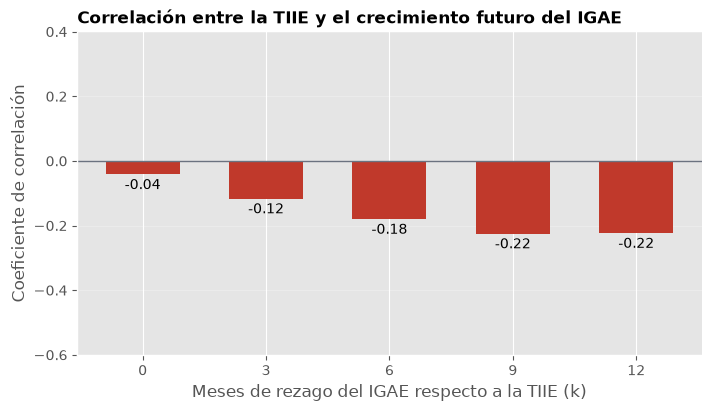

In [9]:
#Gráfica 2
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
colores_corr = [ROJO if v < 0 else AZUL for v in corr_igae["CORRELACION"]]
barras = ax.bar(corr_igae["REZAGO_MESES"].astype(str), corr_igae["CORRELACION"], color=colores_corr, width=0.6)
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.axhline(0, color=GRIS, lw=1)
ax.set_ylim(min(-0.6, corr_igae["CORRELACION"].min() - 0.15), max(0.4, corr_igae["CORRELACION"].max() + 0.15))
ax.set_title("Correlación entre la TIIE y el crecimiento futuro del IGAE", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Meses de rezago del IGAE respecto a la TIIE (k)")
ax.set_ylabel("Coeficiente de correlación")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

fig.savefig("../docs/pregunta3/tiie_igae_rezagos.png", dpi=150)
plt.show()

### 5.5 Limitaciones e interpretación prudente

- **Choques exógenos y pandemia de 2020:** La caída abrupta del IGAE en 2020 y su rebote estadístico en 2021 obedecen al choque sanitario y no a movimientos de la TIIE; este evento extremo introduce ruido en las correlaciones lineales de todo el periodo.
- **Correlación no implica causalidad única:** La actividad económica en México responde simultáneamente al ciclo industrial de Estados Unidos, al tipo de cambio, a la inflación y al gasto público; una correlación bivariada no aísla el efecto puro de la TIIE.
- **Sensibilidad a rezagos largos:** La política monetaria suele operar con rezagos de entre 4 y 8 trimestres en economías emergentes; ventanas superiores a 12 meses podrían capturar efectos adicionales fuera del alcance de esta consulta.
- **Cobertura y pérdida inicial de 12 meses:** aunque el Parquet inicia en `2011-01`, el cálculo de variación anual (`LAG(..., 12)`) reduce la muestra efectiva a 174 meses (`2012-01` a `2026-06`).
- **Alcance:** El presente análisis cubre el eslabón *TIIE → IGAE* del mecanismo de transmisión; su impacto posterior sobre recaudación tributaria y gasto público se aborda en las preguntas correspondientes a finanzas públicas.

### 5.6 Arquitectura aplicada

Recorrido completo de los datos desde las fuentes hasta el consumo analítico de IGAE + TIIE:

```text
 Fuentes (data/raw)     Procesamiento       Almacenamiento          Consulta (Spark SQL)      Resultado Analítico
┌──────────────────┐   ┌───────────────┐   ┌───────────────────┐   ┌─────────────────────┐   ┌────────────────────┐
│ Banxico (TIIE)   │──▶│ Pipeline      │──▶│ macro_finanzas_   │──▶│ Vistas temporales:  │──▶│ Postura monetaria  │
│ INEGI (IGAE/INPC)│   │ PySpark       │   │ consolidado.      │   │ - macro_igae        │   │ + rezagos (k=0..12)│
│ SHCP (Finanzas)  │   │ (ETL/Clean)   │   │ parquet           │   │ - actividad_        │   │ + gráficas PNG en  │
│                  │   │               │   │ (data/processed/) │   │   monetaria         │   │   docs/pregunta3/  │
└──────────────────┘   └───────────────┘   └───────────────────┘   └─────────────────────┘   └────────────────────┘
```

- **Almacenamiento y reutilización:** El dataset consolidado persiste en disco en formato columnar **Parquet** (`data/processed/macro_finanzas_consolidado.parquet`), lo que permite proyectar únicamente las 3 columnas requeridas (`CICLO`, `TIIE`, `MONTO_IGAE_TOTAL`) mediante *column pruning* sin leer el resto de variables fiscales. Las vistas Spark SQL (`macro_igae`, `actividad_monetaria`) se crean en memoria durante la sesión del notebook sin duplicar archivos procesados.
- **Implementado vs. evolución futura:** Actualmente se utiliza almacenamiento local en Parquet + consultas Spark SQL sobre vistas temporales + exportación estática de figuras PNG. Como evolución futura hacia un entorno productivo tipo **Lakehouse (Delta Lake)**, se podrían versionar las tablas consolidadas y materializar las métricas de crecimiento anual (`CREC_IGAE_ANUAL`) dentro de la capa `processed` del pipeline para que múltiples consumidores las reutilicen sin recalcular funciones de ventana.
- **Incorporación de nuevos datos o correcciones:** Al publicarse nuevos cortes mensuales de INEGI o Banxico (o revisiones de cifras preliminares del IGAE), basta con actualizar los archivos fuente en `data/raw/`, reejecutar `pipeline.py` para regenerar el Parquet consolidado y correr nuevamente el notebook; las aserciones de integridad (`assert`) validan automáticamente que no existan nulos, duplicados ni meses faltantes antes de generar los reportes.

### Reproducibilidad del análisis
1. Asegurarse que exista `data/processed/macro_finanzas_consolidado.parquet` ejecutando el pipeline principal.
2. Abrir `notebooks/reporte_de_proyecto.ipynb` en un entorno con `pyspark`, `pandas` y `matplotlib`.
3. Ejecutar en orden las celdas de la **sección 5 (Pregunta Analítica 3)**; las gráficas se guardarán automáticamente en `docs/pregunta3/`.

### 6. Conclusión

El análisis del dataset mensual integrado (2011-01 a 2026-06) muestra que la TIIE se vincula con las finanzas públicas, los precios y la actividad económica, pero con intensidades y rezagos distintos en cada caso:

- **Deuda Pública:** el crecimiento anual de la deuda fue en promedio de 10.47%, y fue mayor en periodos de TIIE acomodaticia (12.39%) que en periodos restrictivos (8.60%). La correlación con la TIIE es negativa en todos los rezagos y se atenúa con el tiempo (de −0.35 sin rezago a −0.12 a 12 meses). El ritmo de endeudamiento responde más a las necesidades presupuestarias y a choques fiscales que al nivel de la tasa de referencia.
- **Inflación y tasa real:** la tasa real fue negativa en 41 de 174 meses (23.6%), con un promedio de 1.91 puntos porcentuales y episodios concentrados en 2013–2014 y 2021–2022. La TIIE reacciona a la inflación con retraso: la correlación sube de 0.38 sin rezago a 0.72 con 12 meses, coherente con una política monetaria que responde a la inflación ya observada.
- **Actividad económica:** el IGAE creció en promedio 1.54% anual, con 1.22% bajo TIIE restrictiva frente a 1.87% bajo TIIE acomodaticia (una brecha de 0.65 puntos porcentuales). La correlación es prácticamente nula sin rezago (−0.04) y alcanza su punto más negativo a los 9 meses (−0.22), lo que sugiere un efecto gradual y moderado.

En conjunto, los resultados describen una transmisión **rezagada y de magnitud moderada**: la TIIE sigue a la inflación con meses de retraso y se asocia con una desaceleración posterior de la actividad, mientras que el vínculo con la deuda es débil y está dominado por factores fiscales.

**Limitaciones.** Los resultados son correlaciones bivariadas sobre una sola serie mensual, por lo que no establecen causalidad. Pesan en particular el choque sanitario de 2020–2021, el tipo de cambio y el entorno externo, la composición de la deuda (tasa fija o variable, interna o externa), el hecho de que la tasa real se calcula ex post y la pérdida de 12 meses iniciales por el cálculo de variaciones anuales.

**Trabajo futuro.** Como siguientes pasos se proponen: incorporar los ingresos y gastos públicos ya disponibles en el dataset para completar el eslabón hacia las finanzas públicas; evaluar modelos multivariados o con rezagos distribuidos; excluir o controlar el periodo 2020–2021; y mover las variaciones anuales al ETL (`enrich.py`) o a una capa de datos versionada (Lakehouse) para que otros consumidores las reutilicen sin recalcular funciones de ventana.